# Setup


In [1]:
import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt



Data Preparation & Preprocessing

    Clean tweets using regex and BeautifulSoup.
    Normalize slang/local words.
    Remove irrelevant tokens (e.g., 'user').

Data Visualization

    Word clouds for each class.
    Label distribution analysis.

Data Transformation

    Tokenization and vocabulary building using torchtext and spaCy.
    Train/validation split.

Model Development- Choose different approach

    
    Custom Transformer architecture implemented in PyTorch.

Training & Validation

    Model training loop with accuracy tracking.
    Evaluation using precision, recall, F1-score, and confusion matrix.

Inference & Deployment

    Model inference on new tweets.
    Results saved to CSV.



In [2]:
data = pd.read_csv('labeled_data.csv')
data.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


# Exploration & Preprocessing

Question: drop "count" or no? Minimum number of count required is always 3, so there is no data that will be missing due to a lesser count. However, perhaps the model can be more confident in its prediction if more people have labelled the data and confirmed the nature of the tweet?

Dropping unwanted columns. Additionally, plotting the classes to check for imbalance.

class labels are as follows: 
- 0 - hate speech 
- 1 - offensive language 
- 2 - neither


In [3]:
#dropping unwanted columns. 
data =data.drop(columns= ['Unnamed: 0', 'hate_speech', 'offensive_language', 'neither'])
data.head()


,count,class,tweet
0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,3,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,3,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,6,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


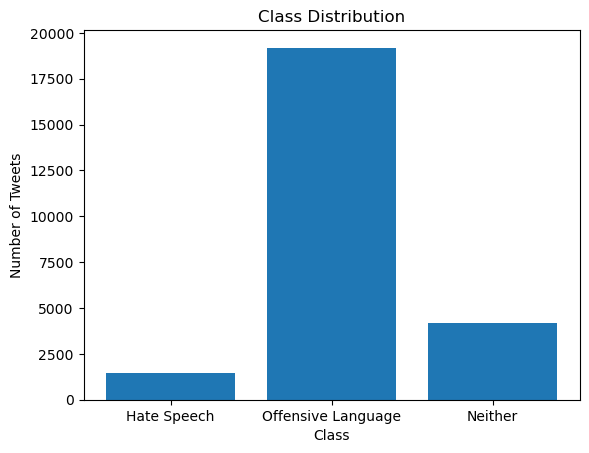

In [4]:
plt.bar(data['class'].value_counts().index, data['class'].value_counts().values)

plt.xlabel('Class')
plt.ylabel('Number of Tweets')
plt.title('Class Distribution')
plt.xticks([0, 1, 2], ['Hate Speech', 'Offensive Language', 'Neither'])

plt.show()


Dataset is clearly heavily imbalanced, most tweets fall under the 'offensive language' label. We need to balance the data.

#### Potential methods to consider:

1) Random Oversampling- oversample (duplicate) the minority data. Data is limited, and I don't want to undersample the majority class so this is a viable option. Caveat is that since we are dealing with textual data, chances of overfitting with so much duplication (considering the high imbalance) is significant. We want the model to learn patterns for diverse kinds of hate speech, and duplicating the same tweets could be counterintuitive. 

2) SMOTE (Synthetic Minority Oversampling Technique)- oversamples the minority class. This is a good option for our usecase, and will be employed in the later stages. 

In [5]:
#Checking null values
data.isna().sum()

count    0
class    0
tweet    0
dtype: int64

Checking data contents

In [6]:
data.tweet.iloc[10]

'" Keeks is a bitch she curves everyone " lol I walked into a conversation like this. Smh'

In [7]:
data.tweet.iloc[100]

'"@ClicquotSuave: LMAOOOOOOOOOOO this nigga @Krillz_Nuh_Care http://t.co/AAnpSUjmYI" &lt;bitch want likes for some depressing shit..foh'

Tweets contain links, mentions, and retweets. We can remove the links by removing anything after "http" up until the next space; remove mentions by removing anything followed directly by an '@', till the next space; and remove the term 'RT' indicating retweets. 

Additionally, the tweets show that there are are special characters that need to be cleaned. 
Although punctuation and numbers can sometimes be important when analyzing text in NLP, for our usecase these do not make much of a difference, since the offensive nature of a tweet rarely depends on grammar/numerical data/punctuation and relies more heavily on slurs or negative stereotypes towards minority groups. Hence, we can get rid of these characters without significant loss of info for the model.

Lastly, we remove any long spaces.

In [8]:
import re

def clean_tweet(tweet):
    tweet = re.sub(r'http\S*', '', tweet) #removing one or more characters that come after 'http' provided they are not spaces
    tweet = re.sub(r'@\S*', '', tweet) #removing usernames
    tweet = re.sub(r'\bRT\b', '', tweet) #removing 'RT'
    tweet = re.sub(r"[^a-zA-Z']", ' ', tweet) #removing anything that isn't lowercase or uppercase alphabets or an apostrophe 
    tweet = re.sub(r'[\s]+', ' ', tweet) 

    return tweet

data['cleaned_tweet'] = data['tweet'].apply(clean_tweet)
data.cleaned_tweet.iloc[100]

' LMAOOOOOOOOOOO this nigga lt bitch want likes for some depressing shit foh'

In [9]:
data = data.drop(columns= 'tweet')
data.head()

,count,class,cleaned_tweet
0,3,2,As a woman you shouldn't complain about clean...
1,3,1,boy dats cold tyga dwn bad for cuffin dat hoe...
2,3,1,Dawg You ever fuck a bitch and she start to c...
3,3,1,she look like a tranny
4,6,1,The shit you hear about me might be true or i...


In [10]:
#Randomly selecting tweets to check for any further cleaning required
data.cleaned_tweet.iloc[2]

' Dawg You ever fuck a bitch and she start to cry You be confused as shit'

In [12]:
#removing leading and trailing whitespaces:
data['cleaned_tweet'] = data['cleaned_tweet'].apply(lambda x: x.strip())
data.cleaned_tweet.iloc[2]

'Dawg You ever fuck a bitch and she start to cry You be confused as shit'

In [20]:
data.cleaned_tweet.iloc[678]

'BlessJesus The Crown of HIS head to the sole of HIS feet'

# NLP

In [30]:
import nltk 
import spacy 
import wordcloud
